In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score
import lightgbm as lgb
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping as xgb_early_stopping
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import warnings


In [28]:
train_label = pd.read_csv("train_label_data.csv")
train_trans = pd.read_csv("train_transaction_data.csv")
member_data = pd.read_csv("member_data.csv")
product_data = pd.read_csv("product_data.csv")
prodgram_data = pd.read_csv("prodgram_data.csv")
train_label.head()

,MemberID,next_buy
0,7ef72aa51aecb701dc5c4074480fcdf6,0
1,577f1b9a093c2cec6398b1118f5d99ab,0
2,e2ee74f248a74ed886a22f14348fbafd,0
3,cefa8ef7469a8b4e6df3f745d4905000,0
4,5eecda17ddf06ed9d79f298b13f84785,0


In [76]:
train_label['next_buy'].value_counts(normalize=True)

next_buy
0    0.93908
1    0.06092
Name: proportion, dtype: float64

Merging files

In [30]:
product_data.rename(columns={'productID': 'FK_PRODUCT_ID'}, inplace=True)
prodgram_data.rename(columns={'prodgramID': 'FK_PROD_GRAM_ID'}, inplace=True)

# Merge train_label with train_transaction_data on MemberID
train = train_trans.merge(train_label, on="MemberID", how="left")

# Merge with product data
train = train.merge(product_data, on="FK_PRODUCT_ID", how="left")

# Merge with prodgram data
train = train.merge(prodgram_data, on="FK_PROD_GRAM_ID", how="left")

# Merge with member data
train = train.merge(member_data, on="MemberID", how="left")

train.head()

,TransactionID,MemberID,Source,FK_PRODUCT_ID,FK_PROD_GRAM_ID,Qty,PricePerUnit,TransactionDatetime,next_buy,ProductName,...,ProductLevel,GrammageName,Point,Price,JoinDate,DateOfBirth,City,NoOfChild,EldestKidDOB,YoungestKidDOB
0,ffd6c035bef03a2c386caf2552148fb2402b0b24,7ef72aa51aecb701dc5c4074480fcdf6,ELANG,27,52,1,NaN,2020-07-01 07:41:00 UTC,0,A,...,Original,700 GR,50,201000.0,2019-12-24,NaN,BEKASI,1,2017-07-31,2017-07-31
1,4fadf10aff7e250cc8d63badeaefdf383c0e1c13,577f1b9a093c2cec6398b1118f5d99ab,ALFAMART,22,39,1,290000.0,2020-07-01 07:24:00 UTC,0,A G,...,Premium,900 GR,100,300000.0,2019-08-29,NaN,JAMBI,2,2017-03-08,2019-01-27
2,7299df1aaf47b52017f58dd8e59df1fe37072670,e2ee74f248a74ed886a22f14348fbafd,EKTONG,22,39,1,263500.0,2020-07-01 09:13:00 UTC,0,A G,...,Premium,900 GR,100,300000.0,2018-06-19,NaN,MAKASAR,2,2017-06-04,2019-04-10
3,22dae0e1e8bb87601eabd712721bd249739bc620,cefa8ef7469a8b4e6df3f745d4905000,CITRA,27,52,3,145000.0,2020-07-01 08:28:00 UTC,0,A,...,Original,700 GR,50,201000.0,2019-05-06,NaN,SIDOARJO,1,2016-11-16,2016-11-16
4,6a744d5d79e09b0c1646e604db1c4ec65eff73d7,5eecda17ddf06ed9d79f298b13f84785,INDOMARET,27,52,1,165900.0,2020-07-01 07:02:00 UTC,0,A,...,Original,700 GR,50,201000.0,2020-05-05,NaN,SUKABUMI,1,2018-05-22,2018-05-22


In [31]:
train.isnull().sum()

TransactionID               0
MemberID                    0
Source                      0
FK_PRODUCT_ID               0
FK_PROD_GRAM_ID             0
Qty                         0
PricePerUnit            19173
TransactionDatetime         0
next_buy                    0
ProductName                 0
ProductCategory             0
ProductLevel                0
GrammageName                0
Point                       0
Price                       0
JoinDate                    0
DateOfBirth            124162
City                        0
NoOfChild                   0
EldestKidDOB                0
YoungestKidDOB              0
dtype: int64

In [32]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130854 entries, 0 to 130853
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   TransactionID        130854 non-null  object 
 1   MemberID             130854 non-null  object 
 2   Source               130854 non-null  object 
 3   FK_PRODUCT_ID        130854 non-null  int64  
 4   FK_PROD_GRAM_ID      130854 non-null  int64  
 5   Qty                  130854 non-null  int64  
 6   PricePerUnit         111681 non-null  float64
 7   TransactionDatetime  130854 non-null  object 
 8   next_buy             130854 non-null  int64  
 9   ProductName          130854 non-null  object 
 10  ProductCategory      130854 non-null  object 
 11  ProductLevel         130854 non-null  object 
 12  GrammageName         130854 non-null  object 
 13  Point                130854 non-null  int64  
 14  Price                130854 non-null  float64
 15  JoinDate         

In [33]:
# Convert date columns to datetime
date_cols = ['TransactionDatetime', 'JoinDate', 'DateOfBirth', 'EldestKidDOB', 'YoungestKidDOB']
for col in date_cols:
    train[col] = pd.to_datetime(train[col], errors='coerce')

In [34]:
print(train.shape)
print(train.head())

(130854, 21)
                              TransactionID                          MemberID  \
0  ffd6c035bef03a2c386caf2552148fb2402b0b24  7ef72aa51aecb701dc5c4074480fcdf6   
1  4fadf10aff7e250cc8d63badeaefdf383c0e1c13  577f1b9a093c2cec6398b1118f5d99ab   
2  7299df1aaf47b52017f58dd8e59df1fe37072670  e2ee74f248a74ed886a22f14348fbafd   
3  22dae0e1e8bb87601eabd712721bd249739bc620  cefa8ef7469a8b4e6df3f745d4905000   
4  6a744d5d79e09b0c1646e604db1c4ec65eff73d7  5eecda17ddf06ed9d79f298b13f84785   

      Source  FK_PRODUCT_ID  FK_PROD_GRAM_ID  Qty  PricePerUnit  \
0      ELANG             27               52    1           NaN   
1   ALFAMART             22               39    1      290000.0   
2     EKTONG             22               39    1      263500.0   
3      CITRA             27               52    3      145000.0   
4  INDOMARET             27               52    1      165900.0   

        TransactionDatetime  next_buy ProductName  ... ProductLevel  \
0 2020-07-01 07:41:00+00:0

In [35]:
train[['Qty', 'Price', 'PricePerUnit']]

,Qty,Price,PricePerUnit
0,1,201000.0,NaN
1,1,300000.0,290000.0
2,1,300000.0,263500.0
3,3,201000.0,145000.0
4,1,201000.0,165900.0
...,...,...,...
130849,1,300000.0,263000.0
130850,1,300000.0,290500.0
130851,4,300000.0,261000.0
130852,2,300000.0,268000.0


Transaction Feature Engineering

In [36]:
train['is_price_missing'] = train['PricePerUnit'].isna().astype(int)

# Impute using median per product
train['PricePerUnit'] = train.groupby('FK_PRODUCT_ID')['PricePerUnit'].transform(
    lambda x: x.fillna(x.median())
)


In [37]:
train['has_dob'] = train['DateOfBirth'].notna().astype(int)
train['age'] = (train['TransactionDatetime'].dt.year - train['DateOfBirth'].dt.year)


In [38]:
train.isnull().sum()

TransactionID               0
MemberID                    0
Source                      0
FK_PRODUCT_ID               0
FK_PROD_GRAM_ID             0
Qty                         0
PricePerUnit                0
TransactionDatetime         0
next_buy                    0
ProductName                 0
ProductCategory             0
ProductLevel                0
GrammageName                0
Point                       0
Price                       0
JoinDate                    0
DateOfBirth            124162
City                        0
NoOfChild                   0
EldestKidDOB                0
YoungestKidDOB              0
is_price_missing            0
has_dob                     0
age                    124162
dtype: int64

In [39]:
member_agg = train.groupby("MemberID").agg({
    "TransactionID": "count",                          # Number of transactions
    "Qty": ["sum", "mean", "max"],                     # Total quantity bought
    "PricePerUnit": ["sum", "mean"],                   # Spending behavior
    "Point": ["sum", "mean"],                          # Loyalty points earned
    "TransactionDatetime": ["min", "max"],             # Time range
})
member_agg.columns = ['_'.join(col).strip() for col in member_agg.columns.values]
member_agg = member_agg.reset_index()


In [40]:
member_agg

,MemberID,TransactionID_count,Qty_sum,Qty_mean,Qty_max,PricePerUnit_sum,PricePerUnit_mean,Point_sum,Point_mean,TransactionDatetime_min,TransactionDatetime_max
0,00010c8a563eb5555709c8ae3120ba2e,1,1,1.000000,1,83000.0,83000.000000,25,25.000000,2021-01-20 16:56:00+00:00,2021-01-20 16:56:00+00:00
1,000184877b42ade87143636847f305a8,1,1,1.000000,1,270000.0,270000.000000,100,100.000000,2020-10-19 20:50:00+00:00,2020-10-19 20:50:00+00:00
2,0003a82569e3202cfecc55d987da0f70,11,15,1.363636,2,3151900.0,286536.363636,1100,100.000000,2021-02-05 18:05:00+00:00,2021-06-27 20:01:00+00:00
3,00045f29692019c0fa274e5330c5dbaf,2,2,1.000000,1,272000.0,136000.000000,100,50.000000,2021-02-12 13:53:00+00:00,2021-03-06 19:18:00+00:00
4,0004aec4786c2b071360a0967b39f4f5,20,20,1.000000,1,3294370.0,164718.500000,1000,50.000000,2020-09-20 19:53:00+00:00,2021-02-18 19:50:00+00:00
...,...,...,...,...,...,...,...,...,...,...,...
40015,fff4f0fdeb6c25ffe024006d4a48abfe,14,32,2.285714,5,3413800.0,243842.857143,1250,89.285714,2020-07-04 10:28:00+00:00,2021-04-03 10:15:00+00:00
40016,fff5aede8d52fe5ae4dc198f4b154328,1,1,1.000000,1,289950.0,289950.000000,100,100.000000,2021-06-22 14:31:00+00:00,2021-06-22 14:31:00+00:00
40017,fff95b42b6b885ac13f1d023a3e77da4,1,1,1.000000,1,297790.0,297790.000000,100,100.000000,2020-11-08 19:23:00+00:00,2020-11-08 19:23:00+00:00
40018,fffe42ed12574370679a3da5c17be903,1,1,1.000000,1,268000.0,268000.000000,100,100.000000,2020-08-20 16:27:00+00:00,2020-08-20 16:27:00+00:00


Recency: Days since last transaction

Frequency: Number of transactions

Monetary: Total spending

In [41]:
# Reference date = max transaction date in dataset (as a proxy for 'today')
reference_date = train['TransactionDatetime'].max()

member_agg['recency_days'] = (reference_date - member_agg['TransactionDatetime_max']).dt.days
member_agg['frequency'] = member_agg['TransactionID_count']
member_agg['monetary'] = member_agg['PricePerUnit_sum']


In [42]:
# Number of unique product categories per member
prod_cat = train.groupby("MemberID")["ProductCategory"].nunique().reset_index(name="unique_categories")

# Most frequent product category per member
top_cat = train.groupby(["MemberID", "ProductCategory"]).size().reset_index(name="count")
top_cat = top_cat.sort_values("count", ascending=False).drop_duplicates("MemberID")[["MemberID", "ProductCategory"]]
top_cat.rename(columns={"ProductCategory": "fav_category"}, inplace=True)

print(prod_cat)
print(top_cat)


                               MemberID  unique_categories
0      00010c8a563eb5555709c8ae3120ba2e                  1
1      000184877b42ade87143636847f305a8                  1
2      0003a82569e3202cfecc55d987da0f70                  1
3      00045f29692019c0fa274e5330c5dbaf                  1
4      0004aec4786c2b071360a0967b39f4f5                  1
...                                 ...                ...
40015  fff4f0fdeb6c25ffe024006d4a48abfe                  1
40016  fff5aede8d52fe5ae4dc198f4b154328                  1
40017  fff95b42b6b885ac13f1d023a3e77da4                  1
40018  fffe42ed12574370679a3da5c17be903                  1
40019  fffedb3153988645aa870224e97e2613                  1

[40020 rows x 2 columns]
                               MemberID fav_category
5736   23b1d579d5e430a7c07ebbd9ac9ac2d0            A
771    04f49c082f13211af88c53b808f24e06            B
29657  b84fe1931acf75567da0984bc732681b            B
28442  b112509af944df04b361491fb8b6c680            A
8

In [43]:
# Merge all features together
features = member_agg.merge(prod_cat, on="MemberID", how="left")
features = features.merge(top_cat, on="MemberID", how="left")


Member Feature Engineering

In [44]:
# Membership duration
# Ensure reference_date is datetime and tz-naive
reference_date = pd.to_datetime(reference_date).tz_localize(None)

# Convert all datetime columns to tz-naive
member_data['JoinDate'] = pd.to_datetime(member_data['JoinDate'], errors='coerce').dt.tz_localize(None)
member_data['DateOfBirth'] = pd.to_datetime(member_data['DateOfBirth'], errors='coerce').dt.tz_localize(None)
member_data['EldestKidDOB'] = pd.to_datetime(member_data['EldestKidDOB'], errors='coerce').dt.tz_localize(None)
member_data['YoungestKidDOB'] = pd.to_datetime(member_data['YoungestKidDOB'], errors='coerce').dt.tz_localize(None)

member_data['membership_days'] = (reference_date - member_data['JoinDate']).dt.days
member_data['age'] = (reference_date - member_data['DateOfBirth']).dt.days // 365


In [45]:
# Age of eldest/youngest kid
member_data['eldest_kid_age'] = (reference_date - member_data['EldestKidDOB']).dt.days // 365
member_data['youngest_kid_age'] = (reference_date - member_data['YoungestKidDOB']).dt.days // 365

# Age gap between kids
member_data['kid_age_gap'] = member_data['eldest_kid_age'] - member_data['youngest_kid_age']


In [46]:
member_data = pd.get_dummies(member_data, columns=['City'], prefix='City')


In [47]:
member_data = member_data.drop(columns=['DateOfBirth', 'JoinDate', 'EldestKidDOB', 'YoungestKidDOB'])


In [48]:
train_features = features.merge(member_data, on='MemberID', how='left')


In [49]:
train_features = train_features.merge(train_label, on='MemberID', how='left')


In [50]:
X = train_features.drop(columns=['MemberID', 'next_buy'])
y = train_features['next_buy']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y,       # keep class balance
    random_state=42
)


In [51]:
print(y.value_counts(normalize=True))


next_buy
0    0.93908
1    0.06092
Name: proportion, dtype: float64


In [52]:


# ==== Preprocess Data ====

# Drop problematic columns for tree models
X_tree = X.drop(columns=['TransactionDatetime_min', 'TransactionDatetime_max', 'fav_category'])

# Define numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Define preprocessors
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combined preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Pipelines
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(use_label_encoder=False, n_estimators=1000, random_state=42))
])

# CV setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {'LogisticRegression': [], 'LightGBM': [], 'XGBoost': []}

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    print(f"\n=== Fold {fold + 1} ===")
    
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # === Logistic Regression ===
    lr_pipeline.fit(X_train, y_train)
    y_pred_lr = lr_pipeline.predict(X_val)
    score_lr = balanced_accuracy_score(y_val, y_pred_lr)
    scores['LogisticRegression'].append(score_lr)
    print(f"LogisticRegression Balanced Accuracy: {score_lr:.4f}")

    # === LightGBM (tree data) ===
    X_train_tree, X_val_tree = X_tree.iloc[train_idx], X_tree.iloc[val_idx]
    lgb_model = LGBMClassifier(
        objective='binary',
        is_unbalance=True,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_estimators=1000
    )
    lgb_model.fit(
        X_train_tree, y_train,
        eval_set=[(X_val_tree, y_val)],
        callbacks=[
            early_stopping(stopping_rounds=50),
            log_evaluation(period=0)
        ]
    )
    y_pred_lgb = lgb_model.predict(X_val_tree)
    score_lgb = balanced_accuracy_score(y_val, y_pred_lgb)
    scores['LightGBM'].append(score_lgb)
    print(f"LightGBM Balanced Accuracy: {score_lgb:.4f}")

    # === XGBoost ===
    imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
    xgb_pipeline.named_steps['classifier'].set_params(scale_pos_weight=imbalance_ratio)
    xgb_pipeline.named_steps['classifier'].fit(
        xgb_pipeline.named_steps['preprocessor'].transform(X_train), y_train
    )
    y_pred_xgb = xgb_pipeline.named_steps['classifier'].predict(
        xgb_pipeline.named_steps['preprocessor'].transform(X_val)
    )
    score_xgb = balanced_accuracy_score(y_val, y_pred_xgb)
    scores['XGBoost'].append(score_xgb)
    print(f"XGBoost Balanced Accuracy: {score_xgb:.4f}")

# Print average scores
print("\n=== Average Balanced Accuracy Scores ===")
for model_name, score_list in scores.items():
    print(f"{model_name}: {np.mean(score_list):.4f}")



=== Fold 1 ===
LogisticRegression Balanced Accuracy: 0.8749
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1951, number of negative: 30065
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006424 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2263
[LightGBM] [Info] Number of data points in the train set: 32016, number of used features: 141
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060938 -> initscore=-2.735020
[LightGBM] [Info] Start training from score -2.735020
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[7]	valid_0's binary_logloss: 0.172163
LightGBM Balanced Accuracy: 0.5000


c:\Users\Lily\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [07:44:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Balanced Accuracy: 0.7639

=== Fold 2 ===
LogisticRegression Balanced Accuracy: 0.8587
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1951, number of negative: 30065
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003005 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2267
[LightGBM] [Info] Number of data points in the train set: 32016, number of used features: 142
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060938 -> initscore=-2.735020
[LightGBM] [Info] Start training from score -2.735020
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[8]	valid_0's binary_logloss: 0.173697
LightGBM Balanced Accuracy: 0.5000


c:\Users\Lily\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [07:44:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Balanced Accuracy: 0.7541

=== Fold 3 ===
LogisticRegression Balanced Accuracy: 0.8807
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1950, number of negative: 30066
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001834 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2265
[LightGBM] [Info] Number of data points in the train set: 32016, number of used features: 138
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060907 -> initscore=-2.735566
[LightGBM] [Info] Start training from score -2.735566
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[7]	valid_0's binary_logloss: 0.172729
LightGBM Balanced Accuracy: 0.5000


...

XGBoost Balanced Accuracy: 0.7679

=== Fold 4 ===
LogisticRegression Balanced Accuracy: 0.8609
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1950, number of negative: 30066
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006143 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2279
[LightGBM] [Info] Number of data points in the train set: 32016, number of used features: 142
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060907 -> initscore=-2.735566
[LightGBM] [Info] Start training from score -2.735566
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[8]	valid_0's binary_logloss: 0.172693
LightGBM Balanced Accuracy: 0.5000


c:\Users\Lily\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [07:44:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Balanced Accuracy: 0.7364

=== Fold 5 ===
LogisticRegression Balanced Accuracy: 0.8703
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1950, number of negative: 30066
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002279 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2276
[LightGBM] [Info] Number of data points in the train set: 32016, number of used features: 142
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.060907 -> initscore=-2.735566
[LightGBM] [Info] Start training from score -2.735566
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[7]	valid_0's binary_logloss: 0.173199
LightGBM Balanced Accuracy: 0.5000


c:\Users\Lily\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:183: UserWarning: [07:44:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Balanced Accuracy: 0.7423

=== Average Balanced Accuracy Scores ===
LogisticRegression: 0.8691
LightGBM: 0.5000
XGBoost: 0.7529


In [53]:
X_tree.columns

Index(['TransactionID_count', 'Qty_sum', 'Qty_mean', 'Qty_max',
       'PricePerUnit_sum', 'PricePerUnit_mean', 'Point_sum', 'Point_mean',
       'recency_days', 'frequency',
       ...
       'City_TULANG BAWANG BARAT', 'City_TULANGBAWANG', 'City_TULUNGAGUNG',
       'City_WAJO', 'City_WAKATOBI', 'City_WAY KANAN', 'City_WONOGIRI',
       'City_WONOSOBO', 'City_YAHUKIMO', 'City_YOGYAKARTA'],
      dtype='object', length=453)

In [54]:
for model in scores:
    avg_score = np.mean(scores[model])
    print(f"\n{model} Average Balanced Accuracy: {avg_score:.4f}")



LogisticRegression Average Balanced Accuracy: 0.8691

LightGBM Average Balanced Accuracy: 0.5000

XGBoost Average Balanced Accuracy: 0.7529


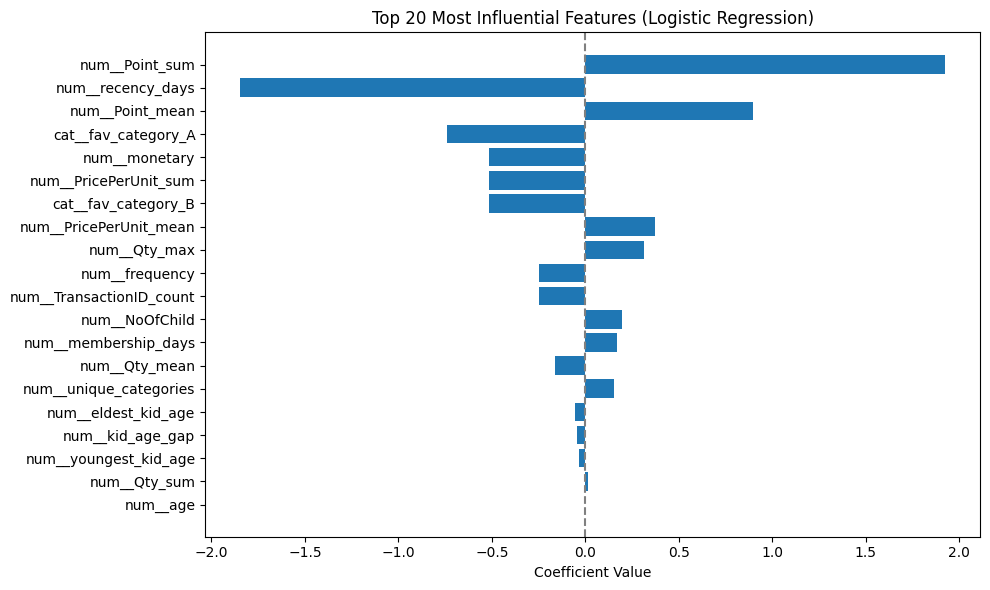

In [55]:


# Get feature names after preprocessing
feature_names = lr_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get coefficients
coefficients = lr_pipeline.named_steps['classifier'].coef_[0]

# Create a DataFrame
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute value of coefficients
top_coef = coef_df.reindex(coef_df.Coefficient.abs().sort_values(ascending=False).index).head(20)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(top_coef['Feature'], top_coef['Coefficient'])
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel("Coefficient Value")
plt.title("Top 20 Most Influential Features (Logistic Regression)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


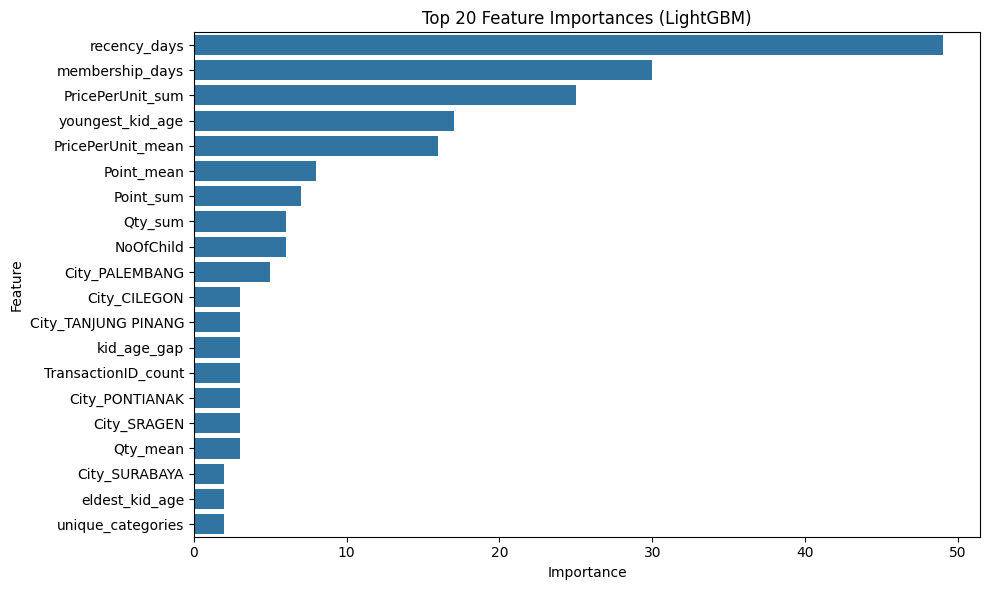

In [56]:


# Get feature importances
lgb_importances = lgb_model.feature_importances_
tree_feature_names = X_tree.columns

# Create DataFrame
lgb_df = pd.DataFrame({
    'Feature': tree_feature_names,
    'Importance': lgb_importances
}).sort_values(by='Importance', ascending=False).head(20)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=lgb_df, x='Importance', y='Feature')
plt.title("Top 20 Feature Importances (LightGBM)")
plt.tight_layout()
plt.show()


c:\Users\Lily\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


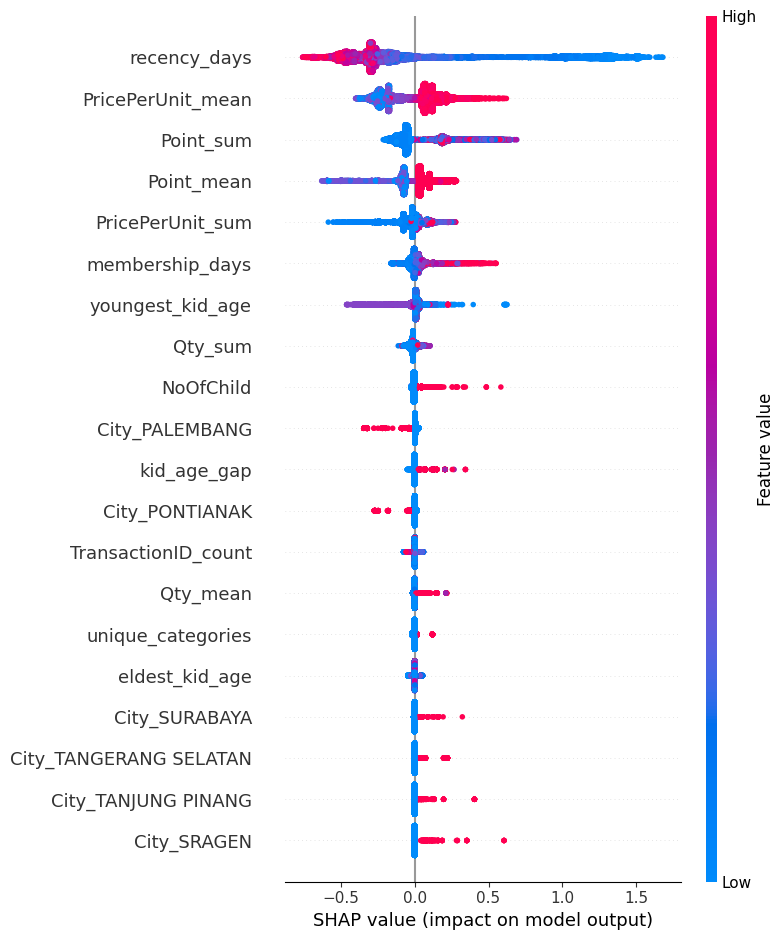

In [57]:
import shap

# 1. Initialize SHAP explainer
explainer = shap.Explainer(lgb_model)

# 2. Use the same data used for training (tree-based models can handle raw features)
shap_values = explainer(X_tree)

# 3. Summary plot (global feature impact)
shap.summary_plot(shap_values, X_tree, max_display=20)



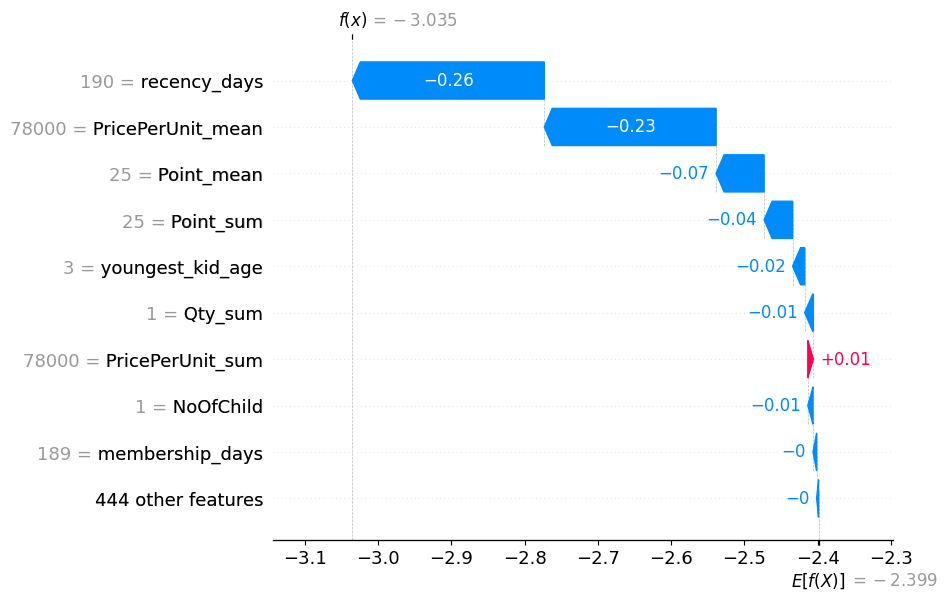

In [58]:
# Pick a customer, e.g., index 123
shap.plots.waterfall(shap_values[123])


In [97]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
from sklearn.base import BaseEstimator
from scipy.stats import loguniform
import random

# Dummy preprocessing pipeline (modify as needed)
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Custom valid combinations generator
def generate_valid_params(n_iter=50, random_state=42):
    rng = np.random.default_rng(random_state)
    valid_params = []
    penalties = ['l1', 'l2', 'elasticnet']
    solvers = ['saga']

    for _ in range(n_iter):
        penalty = rng.choice(penalties)
        solver = 'saga'  # fixed since it's the only one that supports all penalties
        C = loguniform(1e-4, 1e4).rvs(random_state=rng)
        l1_ratio = rng.choice([None, 0.0, 0.25, 0.5, 0.75, 1.0]) if penalty == 'elasticnet' else None

        param = {
            'classifier__penalty': penalty,
            'classifier__solver': solver,
            'classifier__C': C,
        }

        if penalty == 'elasticnet':
            param['classifier__l1_ratio'] = l1_ratio

        valid_params.append(param)

    return valid_params

# Create parameter distribution
param_list = generate_valid_params(n_iter=50, random_state=42)

# Run RandomizedSearchCV with pre-generated valid params
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=param_list,
    scoring='balanced_accuracy',
    n_iter=50,
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

# Fit the model
lr_search.fit(X, y)

# Output best results
print("Best Logistic Regression Params:", lr_search.best_params_)
print("Best Balanced Accuracy:", lr_search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits


KeyboardInterrupt: 

In [98]:
# === Step 1: Buat helper datetime transformer ===
def transform_datetime(df):
    df = df.copy()
    datetime_cols = df.select_dtypes(include=['datetime']).columns
    for col in datetime_cols:
        df[col + '_year'] = df[col].dt.year
        df[col + '_month'] = df[col].dt.month
        df[col + '_day'] = df[col].dt.day
        df[col + '_weekday'] = df[col].dt.weekday
        df.drop(columns=col, inplace=True)
    return df

datetime_transformer = FunctionTransformer(transform_datetime)

# === Step 2: Tentukan kolom numerik ===
numeric_cols = X_train.select_dtypes(include=['number']).columns.tolist()

# === Step 3: Bangun preprocessing pipeline ===
preprocessor = Pipeline(steps=[
    ('datetime', datetime_transformer),
    ('scale', ColumnTransformer(transformers=[
        ('num', Pipeline([
            ('imputer', __import__('sklearn.impute').impute.SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())
        ]), numeric_cols)
    ], remainder='drop'))
])

# === Step 4: Gabungkan dengan classifier Logistic Regression ===
lr_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('classifier', __import__('sklearn.linear_model').linear_model.LogisticRegression(
        max_iter=1000, solver='saga'))
])

# === Step 5: Param grid + tuning ===
param_grid_lr = {
    'classifier__C': loguniform(1e-4, 1e4),
    'classifier__penalty': ['l1', 'l2', 'elasticnet'],
    'classifier__l1_ratio': [None, 0.0, 0.25, 0.5, 0.75, 1.0]
}

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=param_grid_lr,
    scoring='balanced_accuracy',
    n_iter=50,
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42,
    error_score='raise'
)

# === Step 6: Fit ke data ===
lr_search.fit(X_train, y_train)

print("Best Logistic Regression Params:", lr_search.best_params_)
print("Best Balanced Accuracy:", lr_search.best_score_)

# === Step 7: Prediksi dengan threshold ===
best_lr_model = lr_search.best_estimator_
probas = best_lr_model.predict_proba(X_test)[:, 1]
threshold = 0.8
lr_preds = (probas >= threshold).astype(int)

submission_lr = __import__('pandas').DataFrame({
    'MemberID': features_test['MemberID'],
    'next_buy': lr_preds
})
submission_lr.to_csv("lrpercobaan_threshold.csv", index=False)
print("Logistic Regression submission saved as lrpercobaan_threshold.csv")


Fitting 5 folds for each of 50 candidates, totalling 250 fits


ValueError: l1_ratio must be specified when penalty is elasticnet.

In [99]:
from xgboost import XGBClassifier

param_grid_xgb = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 6, 9],
    'min_child_weight': [1, 5, 10],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'n_estimators': [100, 300, 500]
}

xgb_model = XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
    use_label_encoder=False,
    verbosity=0,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid_xgb,
    n_iter=20,
    scoring='balanced_accuracy',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

xgb_search.fit(X_tree, y)
print("Best XGBoost Params:", xgb_search.best_params_)
print("Best Balanced Accuracy:", xgb_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGBoost Params: {'subsample': 0.6, 'n_estimators': 100, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best Balanced Accuracy: 0.8820322092599916


In [88]:
test_trans = pd.read_csv("test_transaction_data.csv")

In [89]:
# 1. Merge product and program data
test = test_trans.merge(product_data, on='FK_PRODUCT_ID', how='left')
test = test.merge(prodgram_data, on='FK_PROD_GRAM_ID', how='left')

# 2. Flag missing price
test['is_price_missing'] = test['PricePerUnit'].isna().astype(int)

# 3. Impute missing PricePerUnit using product-level median
test['PricePerUnit'] = test.groupby('FK_PRODUCT_ID')['PricePerUnit'].transform(
    lambda x: x.fillna(x.median())
)

# 4. Parse transaction datetime
test['TransactionDatetime'] = pd.to_datetime(test['TransactionDatetime'], errors='coerce')

# 5. Get reference date from train
reference_date = train['TransactionDatetime'].max()

# 6. Transaction-level aggregations (per MemberID)
member_agg_test = test.groupby("MemberID").agg({
    "TransactionID": "count",
    "Qty": ["sum", "mean", "max"],
    "PricePerUnit": ["sum", "mean"],
    "Point": ["sum", "mean"],
    "TransactionDatetime": ["min", "max"],
})
member_agg_test.columns = ['_'.join(col).strip() for col in member_agg_test.columns.values]
member_agg_test = member_agg_test.reset_index()

# 7. RFM-like features
member_agg_test['recency_days'] = (reference_date - member_agg_test['TransactionDatetime_max']).dt.days
member_agg_test['frequency'] = member_agg_test['TransactionID_count']
member_agg_test['monetary'] = member_agg_test['PricePerUnit_sum']

# 8. Product category features
prod_cat_test = test.groupby("MemberID")["ProductCategory"].nunique().reset_index(name="unique_categories")
top_cat_test = test.groupby(["MemberID", "ProductCategory"]).size().reset_index(name="count")
top_cat_test = top_cat_test.sort_values("count", ascending=False).drop_duplicates("MemberID")[["MemberID", "ProductCategory"]]
top_cat_test.rename(columns={"ProductCategory": "fav_category"}, inplace=True)

# 9. Merge all features
features_test = member_agg_test.merge(prod_cat_test, on="MemberID", how="left")
features_test = features_test.merge(top_cat_test, on="MemberID", how="left")
features_test = features_test.merge(member_data, on="MemberID", how="left")  # member_data already preprocessed

# 10. Drop unnecessary columns to match training
extra_cols = ['TransactionDatetime_min', 'TransactionDatetime_max', 'fav_category']
X_test = features_test.drop(columns=extra_cols, errors='ignore')

# 11. Align with training features
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# Now X_test is ready for prediction!


In [90]:
# Drop extra columns that were not in training
drop_cols = ['TransactionDatetime_min', 'TransactionDatetime_max', 'fav_category']
X_test_fixed = X_test.drop(columns=drop_cols, errors='ignore')


In [91]:
# Predict with best logistic regression model
best_lr_model = lr_search.best_estimator_
lr_preds = best_lr_model.predict(X_test)

# Ambil probabilitas prediksi kelas 1
lr_proba = best_lr_model.predict_proba(X_test)[:, 1]

# Tentukan threshold, misal 0.3
threshold = 0.7
lr_preds_custom = (lr_proba >= threshold).astype(int)

# Buat submission
submission_lr = pd.DataFrame({
    'MemberID': features_test['MemberID'],
    'next_buy': lr_preds_custom
})
submission_lr.to_csv("lrpercobaan2_threshold03.csv", index=False)
print("Logistic Regression submission (threshold=0.3) saved as lrpercobaan2_threshold03.csv")


# Predict with best XGBoost model
best_xgb_model = xgb_search.best_estimator_

xgb_preds = best_xgb_model.predict(X_test_fixed)

submission_xgb = pd.DataFrame({
    'MemberID': features_test['MemberID'],
    'next_buy': xgb_preds
})
submission_xgb.to_csv("xgbpercobaan2.csv", index=False)
print("XGBoost submission saved as submission_xgb.csv")



AttributeError: 'RandomizedSearchCV' object has no attribute 'best_estimator_'

In [120]:
# Ambil probabilitas kelas 1
xgb_probas = best_xgb_model.predict_proba(X_test_fixed)[:, 1]

# Ubah threshold sesuai kebutuhan (misalnya 0.4)
threshold = 0.815
xgb_preds = (xgb_probas >= threshold).astype(int)

# Simpan ke submission
submission_xgb = pd.DataFrame({
    'MemberID': features_test['MemberID'],
    'next_buy': xgb_preds
})
submission_xgb.to_csv("xgbpercobaan_threshold0_815.csv", index=False)
print("XGBoost submission saved as xgbpercobaan_threshold.csv")


XGBoost submission saved as xgbpercobaan_threshold.csv


In [117]:
xgbresult = pd.read_csv("xgbpercobaan_threshold0_4.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan_threshold0_81.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan_threshold0_75.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan_threshold0_8.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan_threshold0_85.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan_threshold0_7.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

xgbresult = pd.read_csv("xgbpercobaan2.csv")
print(xgbresult['next_buy'].value_counts(normalize=True))
print(xgbresult['next_buy'].value_counts())

lrresult = pd.read_csv('lrpercobaan2.csv')
print(lrresult['next_buy'].value_counts(normalize=True))
print(lrresult['next_buy'].value_counts())

next_buy
0    0.799718
1    0.200282
Name: proportion, dtype: float64
next_buy
0    5103
1    1278
Name: count, dtype: int64
next_buy
0    0.909889
1    0.090111
Name: proportion, dtype: float64
next_buy
0    5806
1     575
Name: count, dtype: int64
next_buy
0    0.895941
1    0.104059
Name: proportion, dtype: float64
next_buy
0    5717
1     664
Name: count, dtype: int64
next_buy
0    0.907225
1    0.092775
Name: proportion, dtype: float64
next_buy
0    5789
1     592
Name: count, dtype: int64
next_buy
0    0.921329
1    0.078671
Name: proportion, dtype: float64
next_buy
0    5879
1     502
Name: count, dtype: int64
next_buy
0    0.881993
1    0.118007
Name: proportion, dtype: float64
next_buy
0    5628
1     753
Name: count, dtype: int64
next_buy
0    0.833412
1    0.166588
Name: proportion, dtype: float64
next_buy
0    5318
1    1063
Name: count, dtype: int64
next_buy
0    0.782949
1    0.217051
Name: proportion, dtype: float64
next_buy
0    4996
1    1385
Name: count, dtype: int64
